# EDA for keywords

keywords.csv - Contains plot keywords for movies as an array of keyword objects.

## 1. Imports

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
import json

## 2. Load data

In [18]:
df = pd.read_csv("../data/keywords.csv") 
df['kw_parsed'] = df['keywords'].apply(ast.literal_eval)

## 3. Struktur 

In [19]:
rows, columns= df.shape
print(f"Rows: {rows}, Columns: {columns}")
df.head()

Rows: 46419, Columns: 3


,id,keywords,kw_parsed
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,...","[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1...","[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392...","[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."
3,31357,"[{'id': 818, 'name': 'based on novel'}, {'id':...","[{'id': 818, 'name': 'based on novel'}, {'id':..."
4,11862,"[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n...","[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n..."


## 4. Missing values

In [23]:
# rows with missing values 
missing = df.isna().sum()
print(f"Missing values per column: {missing}")

# rows where keywords is an empty list
empty_keywords = df["kw_parsed"].str.len() == 0
print(f"Rows with empty keyword list: {empty_keywords.sum()}")

Missing values per column: id           0
keywords     0
kw_parsed    0
dtype: int64
Rows with empty keyword list: 14795


## 5. Duplicates

In [25]:
# identical rows:
print(f"Number of duplicate rows: {df.duplicated(subset=['id', 'keywords']).sum()}")

# duplicates of ID
duplicatedID = df["id"].duplicated().sum()
print(f"Number of duplicate IDs: {duplicatedID}")

Number of duplicate rows: 987
Number of duplicate IDs: 987


### Are the duplicates identical?

In [26]:
dup = df[df["id"].duplicated(keep=False)]
conflicts = (dup.groupby("id")["keywords"].nunique() > 1).sum()
print(f"IDs with different keyword-lists: {conflicts}")
print(dup["id"].value_counts().value_counts().sort_index())

IDs with different keyword-lists: 0
count
2    983
3      2
Name: count, dtype: int64


In [31]:
extra_rows = df[df["id"].duplicated()]
print(f"Duplicates with empty keyword-lists: {(extra_rows['keywords'] == '[]').sum()} av {len(extra_rows)}")

dup.sort_values("id").head(10)

#fjerner duplikatene for resten av EDA !!
df = df.drop_duplicates(subset=["id"]).reset_index(drop=True)

Duplicates with empty keyword-lists: 455 av 987


## 6. Distribution of number of keywords per film

count    45432.000000
mean         3.446954
std          4.690083
min          0.000000
25%          0.000000
50%          2.000000
75%          5.000000
max        149.000000
Name: n_keywords, dtype: float64
count    31092.000000
mean         5.036730
std          4.912728
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max        149.000000
Name: n_keywords, dtype: float64


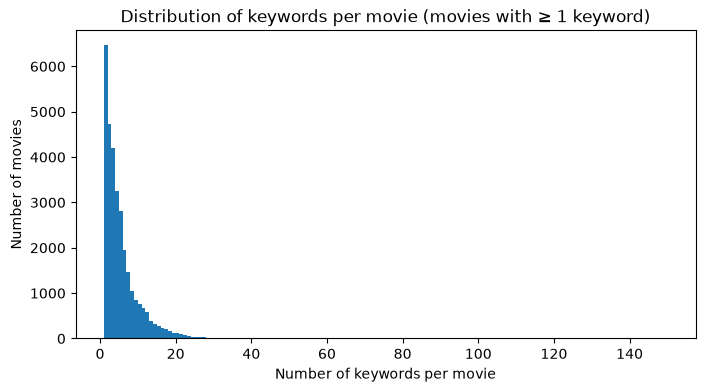

In [34]:
# overview over number of keywords for all films (duplicates removed)
df["n_keywords"] = df["kw_parsed"].str.len()
print(df["n_keywords"].describe())

# overview over number of keywords for films with atleast one keyword (duplicates removed)
non_empty = df[df["n_keywords"] > 0]
print(non_empty["n_keywords"].describe())

# plot to show distribution of keywords per movie for movies with atleast one keyword
plt.figure(figsize=(8, 4))
plt.hist(non_empty["n_keywords"], bins=range(1, non_empty["n_keywords"].max() + 2))
plt.xlabel("Number of keywords per movie")
plt.ylabel("Number of movies")
plt.title("Distribution of keywords per movie (movies with ≥ 1 keyword)")
plt.show()

## 7. Keyword vocabulary

In [36]:
kw = df.explode("kw_parsed").dropna(subset=["kw_parsed"])
kw["kw_id"] = kw["kw_parsed"].str["id"]
kw["kw_name"] = kw["kw_parsed"].str["name"]
print(f"Unique keywords: {kw['kw_id'].nunique()}")
print(kw["kw_name"].value_counts().head(20))
print(f"Keywords used only once: {(kw['kw_id'].value_counts() == 1).sum()}")

Unique keywords: 19956
kw_name
woman director          3039
independent film        1914
murder                  1285
based on novel           822
musical                  726
sex                      679
violence                 647
nudity                   629
revenge                  618
biography                613
suspense                 581
love                     565
female nudity            555
sport                    535
police                   451
duringcreditsstinger     440
teenager                 434
sequel                   432
friendship               404
world war ii             390
Name: count, dtype: int64
Keywords used only once: 8691


In [38]:
names_per_id = kw.groupby("kw_id")["kw_name"].nunique()
print(f"Keyword-ids with more than one name: {(names_per_id > 1).sum()}")

ids_per_name = kw.groupby("kw_name")["kw_id"].nunique()
print(f"Keyword-names with more than one id: {(ids_per_name > 1).sum()}")
print(ids_per_name[ids_per_name > 1].head(10))

Keyword-ids with more than one name: 0
Keyword-names with more than one id: 0
Series([], Name: kw_id, dtype: int64)


## 8. Findings and decisions

| Finding | Decision |
|---|---|
|There are 987 fully identical rows in the dataset. 983 of the IDs appear twice, while 2 of them appear three times | Remove the duplicates |
|There are 14 795 rows with empty keywords lists. This accounts for nearly a third of the rows| |
|The median number of keywords per movie is is 2 for all movies, and 4 for movies with at least one keyword. 75 % of movies with keywords have 6 or fewer. Max is 149. | |
|There are 19 956 unique keywords. 8 691 of them (43.6 %) are used in only one movie. | |
|Each keyword id maps to exactly one name, and each name to exactly one id. | |
| | |
| | |
| | |
| | |